# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

In [29]:
# Importaciones generales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
# Datasets y modelos
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
# Métricas
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
# Clasificación
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
# Regresión
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
# Configuración
np.random.seed(42)
sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)
Características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases: ['setosa' 'versicolor' 'virginica']
Conteo por clase: [50 50 50]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


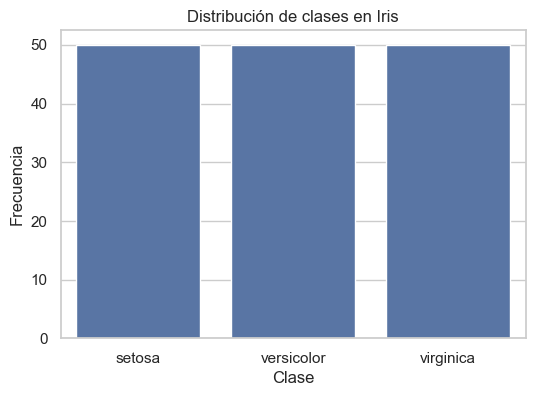

In [30]:
# Cargar Iris
iris = datasets.load_iris()
X = iris.data
y = iris.target
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Características:", iris.feature_names)
print("Clases:", iris.target_names)
print("Conteo por clase:", np.bincount(y))
# Tabla con 5 ejemplos
df_iris = pd.DataFrame(X, columns=iris.feature_names)
df_iris["target"] = y
df_iris["target_name"] = df_iris["target"].map(dict(enumerate(iris.target_names)))
display(df_iris.head())
# Distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(data=df_iris, x="target_name", order=iris.target_names)
plt.title("Distribución de clases en Iris")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.show()

**Resumen:**
- Cada instancia representa una flor de iris.
- Instancias: 150; características: 4 variables numéricas continuas, medidas en centímetros.
- Características: `sepal length` (largo del sépalo), `sepal width` (ancho del sépalo), `petal length` (largo del pétalo) y `petal width` (ancho del pétalo).
- Clases: *setosa*, *versicolor* y *virginica*, balanceadas (50 ejemplos por clase).
- Dimensiones: X = (150, 4); y = (150,).

# 2. Comparación de clasificadores

## Predicciones iniciales

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
   - La regresión logística, SVM y MLP, porque usan productos punto, regularización o métodos de optimización sensibles a las escalas. Los árboles y sus ensambles, y Gaussian Naive Bayes, son menos sensibles.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
   - La regresión logística y SVM lineal producen fronteras lineales; Gaussian Naive Bayes también suele dar fronteras simples.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
   - Porque el resultado depende de los datos, la partición, el ruido, los hiperparámetros y los supuestos de cada modelo.

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

In [31]:
# Partición estratificada: 60% train, 20% validación, 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)
print("Train:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (90, 4) (90,)
Validación: (30, 4) (30,)
Test: (30, 4) (30,)


In [32]:
# Modelos iniciales
modelos_clf = {
    "GaussianNB": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", GaussianNB())
    ]),
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "SVM_lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="linear", C=1.0, random_state=42))
    ]),
    "DecisionTree": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", DecisionTreeClassifier(random_state=42))
    ]),
    "RandomForest": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    "GradientBoosting": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", GradientBoostingClassifier(random_state=42))
    ]),
    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=(50,), max_iter=2000, random_state=42))
    ])
}

# Evaluación en validación
print("Evaluación inicial en validación:")
for nombre, modelo in modelos_clf.items():
    modelo.fit(X_train, y_train)
    y_val_pred = modelo.predict(X_val)
    acc = accuracy_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred, average="macro")
    print(f"{nombre:20s} | Accuracy={acc:.4f} | F1 macro={f1:.4f}")

Evaluación inicial en validación:
GaussianNB           | Accuracy=0.9333 | F1 macro=0.9333
LogisticRegression   | Accuracy=0.9333 | F1 macro=0.9333
SVM_lineal           | Accuracy=0.9333 | F1 macro=0.9333
DecisionTree         | Accuracy=0.9333 | F1 macro=0.9333
RandomForest         | Accuracy=0.9333 | F1 macro=0.9333
GradientBoosting     | Accuracy=0.9000 | F1 macro=0.8997
MLP                  | Accuracy=0.9333 | F1 macro=0.9333


## Ajustes limitados usando validación

Ajustamos algunos hiperparámetros de SVM lineal y MLP.  
No usamos test para decidir.

In [33]:
# Ajuste de SVM lineal
best_C = 1.0
best_f1_svm = -1

print("Tuning SVM lineal:")
for C in [0.01, 0.1, 1, 10, 100]:
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="linear", C=C, random_state=42))
    ])
    modelo.fit(X_train, y_train)
    y_val_pred = modelo.predict(X_val)
    f1 = f1_score(y_val, y_val_pred, average="macro")
    print(f"C={C:6.2f} | F1 macro={f1:.4f}")
    if f1 > best_f1_svm:
        best_f1_svm = f1
        best_C = C

print("Mejor C:", best_C, "F1:", best_f1_svm)

# Ajuste de MLP
best_hidden = (50,)
best_alpha = 0.0001
best_f1_mlp = -1

print("\nTuning MLP:")
for hidden in [(10,), (50,), (100,), (50, 50)]:
    for alpha in [0.0001, 0.001, 0.01]:
        modelo = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha,
                                  max_iter=2000, random_state=42))
        ])
        modelo.fit(X_train, y_train)
        y_val_pred = modelo.predict(X_val)
        f1 = f1_score(y_val, y_val_pred, average="macro")
        print(f"hidden={hidden}, alpha={alpha} | F1 macro={f1:.4f}")
        if f1 > best_f1_mlp:
            best_f1_mlp = f1
            best_hidden = hidden
            best_alpha = alpha

print("Mejor MLP:", best_hidden, "alpha:", best_alpha, "F1:", best_f1_mlp)

Tuning SVM lineal:
C=  0.01 | F1 macro=0.8329
C=  0.10 | F1 macro=0.9333
C=  1.00 | F1 macro=0.9333
C= 10.00 | F1 macro=0.8997
C=100.00 | F1 macro=0.8997
Mejor C: 0.1 F1: 0.9333333333333332

Tuning MLP:
hidden=(10,), alpha=0.0001 | F1 macro=0.9333
hidden=(10,), alpha=0.001 | F1 macro=0.9333
hidden=(10,), alpha=0.01 | F1 macro=0.9333
hidden=(50,), alpha=0.0001 | F1 macro=0.9333
hidden=(50,), alpha=0.001 | F1 macro=0.9333
hidden=(50,), alpha=0.01 | F1 macro=0.9333
hidden=(100,), alpha=0.0001 | F1 macro=0.9333
hidden=(100,), alpha=0.001 | F1 macro=0.9333
hidden=(100,), alpha=0.01 | F1 macro=0.9333
hidden=(50, 50), alpha=0.0001 | F1 macro=0.9333
hidden=(50, 50), alpha=0.001 | F1 macro=0.9333
hidden=(50, 50), alpha=0.01 | F1 macro=0.9333
Mejor MLP: (10,) alpha: 0.0001 F1: 0.9333333333333332


In [34]:
# Modelos finales con hiperparámetros congelados
modelos_finales = {
    "GaussianNB": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", GaussianNB())
    ]),
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "SVM_lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="linear", C=best_C, random_state=42))
    ]),
    "DecisionTree": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", DecisionTreeClassifier(random_state=42))
    ]),
    "RandomForest": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    "GradientBoosting": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", GradientBoostingClassifier(random_state=42))
    ]),
    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=best_hidden, alpha=best_alpha,
                              max_iter=2000, random_state=42))
    ])
}

# Evaluación final sobre test
resultados_test = []
for nombre, modelo in modelos_finales.items():
    modelo.fit(X_train_val, y_train_val)   # entrenamos con train + validación
    y_test_pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred, average="macro")
    resultados_test.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": str(modelo.named_steps["clf"]) if "clf" in modelo.named_steps else "",
        "Accuracy test": acc,
        "F1 macro test": f1
    })

df_resultados_clf = pd.DataFrame(resultados_test)
display(df_resultados_clf)

,Modelo,Transformación,Hiperparámetros principales,Accuracy test,F1 macro test
0,GaussianNB,StandardScaler,GaussianNB(),0.966667,0.966583
1,LogisticRegression,StandardScaler,"LogisticRegression(max_iter=1000, random_state...",0.933333,0.933333
2,SVM_lineal,StandardScaler,"SVC(C=0.1, kernel='linear', random_state=42)",0.933333,0.933333
3,DecisionTree,StandardScaler,DecisionTreeClassifier(random_state=42),0.933333,0.933333
4,RandomForest,StandardScaler,RandomForestClassifier(random_state=42),0.900000,0.899749
5,GradientBoosting,StandardScaler,GradientBoostingClassifier(random_state=42),0.966667,0.966583
6,MLP,StandardScaler,"MLPClassifier(hidden_layer_sizes=(10,), max_it...",0.966667,0.966583


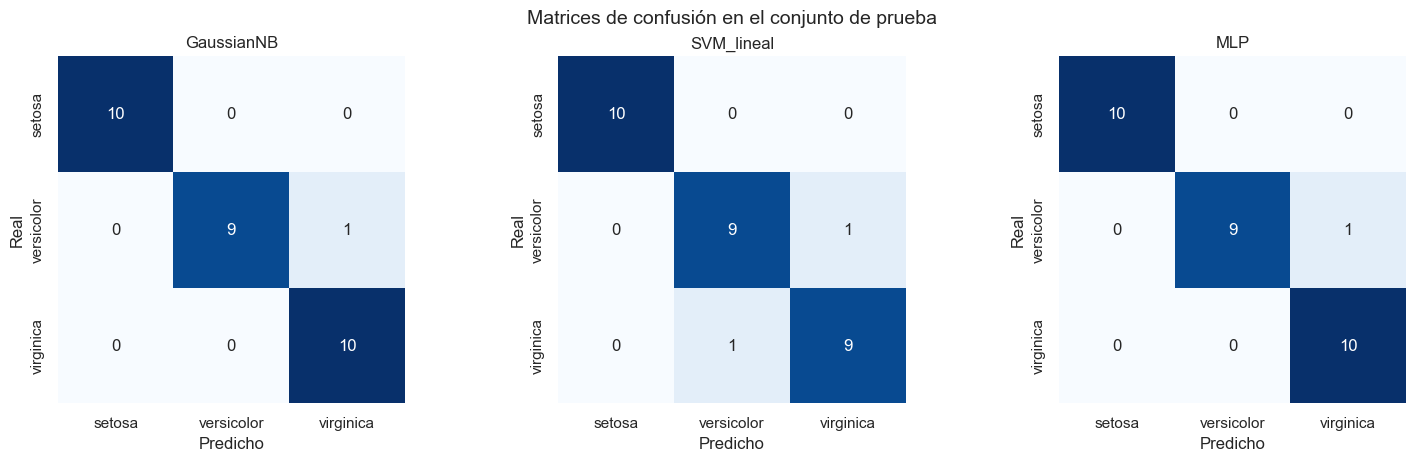


Reporte de clasificación - GaussianNB
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Reporte de clasificación - SVM_lineal
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Reporte de clasificación - MLP
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       

In [35]:
# Matrices de confusión comparables para Naive Bayes, SVM lineal y MLP
nombres_cm = ["GaussianNB", "SVM_lineal", "MLP"]
matrices_cm = []
predicciones_cm = {}

for nombre in nombres_cm:
    modelo = modelos_finales[nombre]
    modelo.fit(X_train_val, y_train_val)
    y_test_pred = modelo.predict(X_test)
    predicciones_cm[nombre] = y_test_pred
    matrices_cm.append(
        confusion_matrix(y_test, y_test_pred, labels=np.arange(len(iris.target_names)))
    )

# Se comparte la escala de color para facilitar la comparación entre modelos.
vmax_cm = max(cm.max() for cm in matrices_cm)
fig, axes = plt.subplots(1, len(nombres_cm), figsize=(15, 4.5), constrained_layout=True)

for ax, nombre, cm in zip(axes, nombres_cm, matrices_cm):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        vmin=0,
        vmax=vmax_cm,
        cbar=False,
        square=True,
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )
    ax.set_title(nombre)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

fig.suptitle("Matrices de confusión en el conjunto de prueba", fontsize=14)
plt.show()

for nombre in nombres_cm:
    print(f"\nReporte de clasificación - {nombre}")
    print(classification_report(
        y_test,
        predicciones_cm[nombre],
        labels=np.arange(len(iris.target_names)),
        target_names=iris.target_names,
        zero_division=0
    ))

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
   - GaussianNB, GradientBoosting y MLP empataron en esta partición: accuracy = 0.9667 y F1 macro = 0.9666. No hay un único ganador.

2. ¿Cuál fue el modelo más sencillo de programar?
   - GaussianNB, porque no requiere ajustar hiperparámetros y su implementación es directa.

3. ¿Accuracy y F1 macro cuentan la misma historia?
   - En estos resultados son prácticamente iguales: las clases están balanceadas y las métricas por clase son parecidas.

4. ¿Cuál es la diferencia entre macro y micro?
   - Macro promedia la métrica de cada clase dándoles el mismo peso. Micro agrega los aciertos y errores antes de calcularla; en clasificación multiclase de una sola etiqueta, micro-F1 es igual a accuracy, incluso si las clases no están balanceadas.

5. ¿Qué aporta el MLP frente a un modelo lineal?
   - Puede aprender fronteras no lineales, pero en esta prueba no superó a GaussianNB ni a GradientBoosting.

### Análisis de dos errores de clasificación

Se examinaron los dos primeros errores del SVM lineal en prueba:

1. Índice 23: clase real *virginica*, predicha *versicolor*. Características: largo del sépalo = 6.1 cm, ancho del sépalo = 2.6 cm, largo del pétalo = 5.6 cm y ancho del pétalo = 1.4 cm.
2. Índice 25: clase real *versicolor*, predicha *virginica*. Características: largo del sépalo = 6.7 cm, ancho del sépalo = 3.0 cm, largo del pétalo = 5.0 cm y ancho del pétalo = 1.7 cm.

Los dos errores son confusiones entre *versicolor* y *virginica*, cuyas medidas pueden solaparse. Estos ejemplos muestran qué predicciones fallaron y con qué características; por sí solos no permiten identificar una causa biológica, un error de medición ni una relación causal.

# 3. Comparación de modelos de regresión

## Dataset Diabetes

Cargamos Diabetes de scikit-learn. El objetivo numérico mide la progresión de la diabetes un año después de la línea base. Las características incluidas en el dataset ya están escaladas, por lo que no deben interpretarse como unidades clínicas directas.

## Predicción inicial

¿Un modelo más flexible produce siempre menor error en datos nuevos?

**Predicción:** No necesariamente. Un modelo más flexible puede sobreajustarse y rendir peor en datos nuevos; la validación permite comparar configuraciones sin usar el conjunto de prueba.

In [36]:
# Cargar Diabetes
diabetes = datasets.load_diabetes()
X = diabetes.data
y = diabetes.target

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Características:", diabetes.feature_names)
print("\nDescripción (fragmento):")
print(diabetes.DESCR[:1200])

df_diabetes = pd.DataFrame(X, columns=diabetes.feature_names)
df_diabetes["target"] = y
display(df_diabetes.head())
print(df_diabetes.describe())

Dimensiones de X: (442, 10)
Dimensiones de y: (442,)
Características: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Descripción (fragmento):
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total choles

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3            s4            s5            s6  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean   3.918434e-17 -5.777179e-18 -9.042540e-18  9.293722e-17  1.130318e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

In [37]:
# Partición: 60% train, 20% validación, 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

print("Train:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (264, 10) (264,)
Validación: (89, 10) (89,)
Test: (89, 10) (89,)


In [38]:
# Función RMSE
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Modelos iniciales de regresión
modelos_reg = {
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Ridge(alpha=1.0, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Lasso(alpha=0.1, max_iter=10000, random_state=42))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", KNeighborsRegressor(n_neighbors=5))
    ]),
    "DecisionTree": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", DecisionTreeRegressor(random_state=42))
    ]),
    "RandomForest": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", RandomForestRegressor(n_estimators=100, random_state=42))
    ]),
    "GradientBoosting": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", GradientBoostingRegressor(random_state=42))
    ]),
    "MLP": TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("reg", MLPRegressor(hidden_layer_sizes=(100,), max_iter=2000, random_state=42))
        ]),
        transformer=StandardScaler()
    )
}

# Evaluación en validación
print("Evaluación inicial en validación:")
for nombre, modelo in modelos_reg.items():
    modelo.fit(X_train, y_train)
    y_val_pred = modelo.predict(X_val)
    mae = mean_absolute_error(y_val, y_val_pred)
    rmse_val = rmse(y_val, y_val_pred)
    r2 = r2_score(y_val, y_val_pred)
    print(f"{nombre:20s} | MAE={mae:.2f} | RMSE={rmse_val:.2f} | R²={r2:.4f}")

Evaluación inicial en validación:
LinearRegression     | MAE=42.94 | RMSE=51.19 | R²=0.5216
Ridge                | MAE=42.72 | RMSE=51.10 | R²=0.5233
Lasso                | MAE=42.64 | RMSE=51.10 | R²=0.5234
KNN                  | MAE=45.29 | RMSE=56.83 | R²=0.4105
DecisionTree         | MAE=50.55 | RMSE=66.10 | R²=0.2025
RandomForest         | MAE=44.44 | RMSE=54.15 | R²=0.4648
GradientBoosting     | MAE=44.62 | RMSE=53.87 | R²=0.4703
MLP                  | MAE=53.69 | RMSE=66.59 | R²=0.1908


In [39]:
# Ajuste limitado de KNN y MLP usando validación
best_knn_k = 5
best_rmse_knn = np.inf

print("Tuning KNN:")
for k in [1, 3, 5, 7, 9, 11]:
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("reg", KNeighborsRegressor(n_neighbors=k))
    ])
    modelo.fit(X_train, y_train)
    y_val_pred = modelo.predict(X_val)
    rmse_val = rmse(y_val, y_val_pred)
    print(f"k={k:2d} | RMSE validación={rmse_val:.2f}")
    if rmse_val < best_rmse_knn:
        best_rmse_knn = rmse_val
        best_knn_k = k

print("Mejor k:", best_knn_k, "RMSE:", best_rmse_knn)

best_mlp_hidden = (100,)
best_mlp_alpha = 0.0001
best_rmse_mlp = np.inf

print("\nTuning MLP:")
for hidden in [(50,), (100,), (50, 50)]:
    for alpha in [0.0001, 0.001, 0.01]:
        modelo = TransformedTargetRegressor(
            regressor=Pipeline([
                ("scaler", StandardScaler()),
                ("reg", MLPRegressor(hidden_layer_sizes=hidden, alpha=alpha,
                                     max_iter=2000, random_state=42))
            ]),
            transformer=StandardScaler()
        )
        modelo.fit(X_train, y_train)
        y_val_pred = modelo.predict(X_val)
        rmse_val = rmse(y_val, y_val_pred)
        print(f"hidden={hidden}, alpha={alpha} | RMSE validación={rmse_val:.2f}")
        if rmse_val < best_rmse_mlp:
            best_rmse_mlp = rmse_val
            best_mlp_hidden = hidden
            best_mlp_alpha = alpha

print("Mejor MLP:", best_mlp_hidden, "alpha:", best_mlp_alpha, "RMSE:", best_rmse_mlp)
# Ajuste limitado de árbol, Random Forest y Gradient Boosting usando validación
best_decision_tree_params = None
best_rmse_tree = np.inf
for max_depth in [None, 3, 5, 10]:
    for min_samples_leaf in [1, 5]:
        modelo = Pipeline([
            ("scaler", StandardScaler()),
            ("reg", DecisionTreeRegressor(max_depth=max_depth,
                                           min_samples_leaf=min_samples_leaf,
                                           random_state=42))
        ])
        modelo.fit(X_train, y_train)
        rmse_val = rmse(y_val, modelo.predict(X_val))
        if rmse_val < best_rmse_tree:
            best_rmse_tree = rmse_val
            best_decision_tree_params = {
                "max_depth": max_depth,
                "min_samples_leaf": min_samples_leaf
            }
print("Mejor árbol:", best_decision_tree_params, "RMSE validación:", best_rmse_tree)

best_random_forest_params = None
best_rmse_forest = np.inf
for n_estimators in [100, 200]:
    for max_depth in [None, 5]:
        for min_samples_leaf in [1, 5]:
            modelo = Pipeline([
                ("scaler", StandardScaler()),
                ("reg", RandomForestRegressor(n_estimators=n_estimators,
                                               max_depth=max_depth,
                                               min_samples_leaf=min_samples_leaf,
                                               random_state=42))
            ])
            modelo.fit(X_train, y_train)
            rmse_val = rmse(y_val, modelo.predict(X_val))
            if rmse_val < best_rmse_forest:
                best_rmse_forest = rmse_val
                best_random_forest_params = {
                    "n_estimators": n_estimators,
                    "max_depth": max_depth,
                    "min_samples_leaf": min_samples_leaf
                }
print("Mejor Random Forest:", best_random_forest_params,
      "RMSE validación:", best_rmse_forest)

best_gradient_boosting_params = None
best_rmse_boosting = np.inf
for n_estimators in [100, 200]:
    for learning_rate in [0.03, 0.1]:
        for max_depth in [1, 2]:
            modelo = Pipeline([
                ("scaler", StandardScaler()),
                ("reg", GradientBoostingRegressor(n_estimators=n_estimators,
                                                  learning_rate=learning_rate,
                                                  max_depth=max_depth,
                                                  random_state=42))
            ])
            modelo.fit(X_train, y_train)
            rmse_val = rmse(y_val, modelo.predict(X_val))
            if rmse_val < best_rmse_boosting:
                best_rmse_boosting = rmse_val
                best_gradient_boosting_params = {
                    "n_estimators": n_estimators,
                    "learning_rate": learning_rate,
                    "max_depth": max_depth
                }
print("Mejor Gradient Boosting:", best_gradient_boosting_params,
      "RMSE validación:", best_rmse_boosting)

Tuning KNN:
k= 1 | RMSE validación=75.71
k= 3 | RMSE validación=61.60
k= 5 | RMSE validación=56.83
k= 7 | RMSE validación=56.79
k= 9 | RMSE validación=55.41
k=11 | RMSE validación=54.09
Mejor k: 11 RMSE: 54.09440422695612

Tuning MLP:
hidden=(50,), alpha=0.0001 | RMSE validación=68.33
hidden=(50,), alpha=0.001 | RMSE validación=68.15
hidden=(50,), alpha=0.01 | RMSE validación=69.27
hidden=(100,), alpha=0.0001 | RMSE validación=66.59
hidden=(100,), alpha=0.001 | RMSE validación=68.64
hidden=(100,), alpha=0.01 | RMSE validación=66.49
hidden=(50, 50), alpha=0.0001 | RMSE validación=74.69
hidden=(50, 50), alpha=0.001 | RMSE validación=75.24
hidden=(50, 50), alpha=0.01 | RMSE validación=73.71
Mejor MLP: (100,) alpha: 0.01 RMSE: 66.4934527203209
Mejor árbol: {'max_depth': 3, 'min_samples_leaf': 5} RMSE validación: 57.35650842964841
Mejor Random Forest: {'n_estimators': 200, 'max_depth': 5, 'min_samples_leaf': 5} RMSE validación: 53.639141594630836
Mejor Gradient Boosting: {'n_estimators': 20

Ridge:


,alpha,RMSE_train,RMSE_val,sum_abs_coef
0,0.001,54.610364,51.193496,198.217339
1,0.010,54.610371,51.191558,197.670167
2,0.100,54.611033,51.174071,192.447245
3,1.000,54.643849,51.103145,156.990363
4,10.000,54.842556,51.160459,108.883328
5,100.000,55.859422,51.736930,87.802642


Lasso:


,alpha,RMSE_train,RMSE_val,sum_abs_coef,n_cero
0,0.001,54.610368,51.192046,197.799229,0
1,0.010,54.610805,51.177697,193.487298,0
2,0.100,54.654421,51.099703,150.425187,0
3,1.000,54.912377,51.060247,100.612134,1
4,10.000,58.425064,53.151103,52.748687,6
5,100.000,78.846190,75.639205,0.000000,10


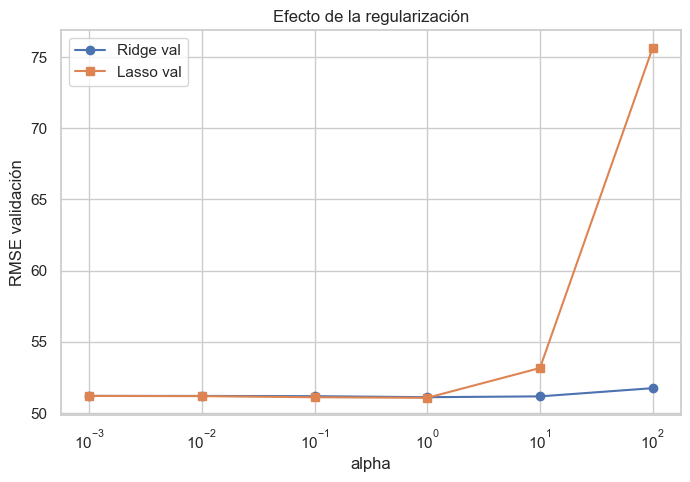

Alpha de Ridge seleccionado por RMSE de validación: 1
Alpha de Lasso seleccionado por RMSE de validación: 1


In [40]:
# Regularización: Ridge y Lasso
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

# Ridge
ridge_resultados = []
for alpha in alphas:
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Ridge(alpha=alpha, random_state=42))
    ])
    modelo.fit(X_train, y_train)
    train_pred = modelo.predict(X_train)
    val_pred = modelo.predict(X_val)
    coef = modelo.named_steps["reg"].coef_
    ridge_resultados.append({
        "alpha": alpha,
        "RMSE_train": rmse(y_train, train_pred),
        "RMSE_val": rmse(y_val, val_pred),
        "sum_abs_coef": np.sum(np.abs(coef))
    })

print("Ridge:")
display(pd.DataFrame(ridge_resultados))

# Lasso
lasso_resultados = []
for alpha in alphas:
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Lasso(alpha=alpha, max_iter=10000, random_state=42))
    ])
    modelo.fit(X_train, y_train)
    train_pred = modelo.predict(X_train)
    val_pred = modelo.predict(X_val)
    coef = modelo.named_steps["reg"].coef_
    lasso_resultados.append({
        "alpha": alpha,
        "RMSE_train": rmse(y_train, train_pred),
        "RMSE_val": rmse(y_val, val_pred),
        "sum_abs_coef": np.sum(np.abs(coef)),
        "n_cero": np.sum(coef == 0)
    })

print("Lasso:")
display(pd.DataFrame(lasso_resultados))

# Gráfico comparativo
plt.figure(figsize=(8, 5))
plt.plot(alphas, [r["RMSE_val"] for r in ridge_resultados], marker="o", label="Ridge val")
plt.plot(alphas, [r["RMSE_val"] for r in lasso_resultados], marker="s", label="Lasso val")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("RMSE validación")
plt.title("Efecto de la regularización")
plt.legend()
plt.show()
best_alpha_ridge = min(ridge_resultados, key=lambda resultado: resultado["RMSE_val"])["alpha"]
best_alpha_lasso = min(lasso_resultados, key=lambda resultado: resultado["RMSE_val"])["alpha"]
print("Alpha de Ridge seleccionado por RMSE de validación:", best_alpha_ridge)
print("Alpha de Lasso seleccionado por RMSE de validación:", best_alpha_lasso)

In [41]:
# Modelos finales de regresión
modelos_reg_finales = {
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Ridge(alpha=best_alpha_ridge, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Lasso(alpha=best_alpha_lasso, max_iter=10000, random_state=42))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", KNeighborsRegressor(n_neighbors=best_knn_k))
    ]),
    "DecisionTree": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", DecisionTreeRegressor(**best_decision_tree_params, random_state=42))
    ]),
    "RandomForest": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", RandomForestRegressor(**best_random_forest_params, random_state=42))
    ]),
    "GradientBoosting": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", GradientBoostingRegressor(**best_gradient_boosting_params, random_state=42))
    ]),
    "MLP": TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("reg", MLPRegressor(hidden_layer_sizes=best_mlp_hidden,
                                 alpha=best_mlp_alpha,
                                 max_iter=2000,
                                 random_state=42))
        ]),
        transformer=StandardScaler()
    )
}

# Evaluación final en test
resultados_reg_test = []
for nombre, modelo in modelos_reg_finales.items():
    modelo.fit(X_train_val, y_train_val)
    y_test_pred = modelo.predict(X_test)
    mae = mean_absolute_error(y_test, y_test_pred)
    rmse_test = rmse(y_test, y_test_pred)
    r2 = r2_score(y_test, y_test_pred)
    resultados_reg_test.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse_test,
        "R²": r2
    })

df_resultados_reg = pd.DataFrame(resultados_reg_test)
display(df_resultados_reg)

,Modelo,MAE,RMSE,R²
0,LinearRegression,42.794095,53.853446,0.452603
1,Ridge,42.811999,53.777454,0.454147
2,Lasso,42.802984,53.146666,0.466877
3,KNN,45.589377,55.665924,0.415137
4,DecisionTree,45.181308,55.628206,0.415929
5,RandomForest,43.454079,53.461538,0.460541
6,GradientBoosting,42.550309,52.396181,0.481827
7,MLP,46.017222,59.933429,0.322025


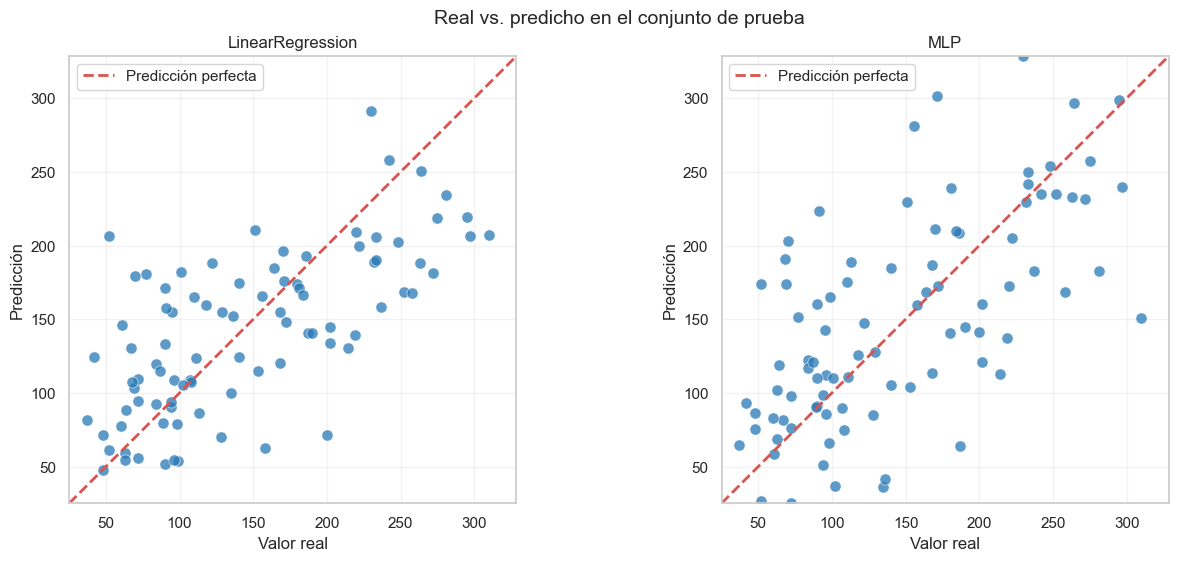

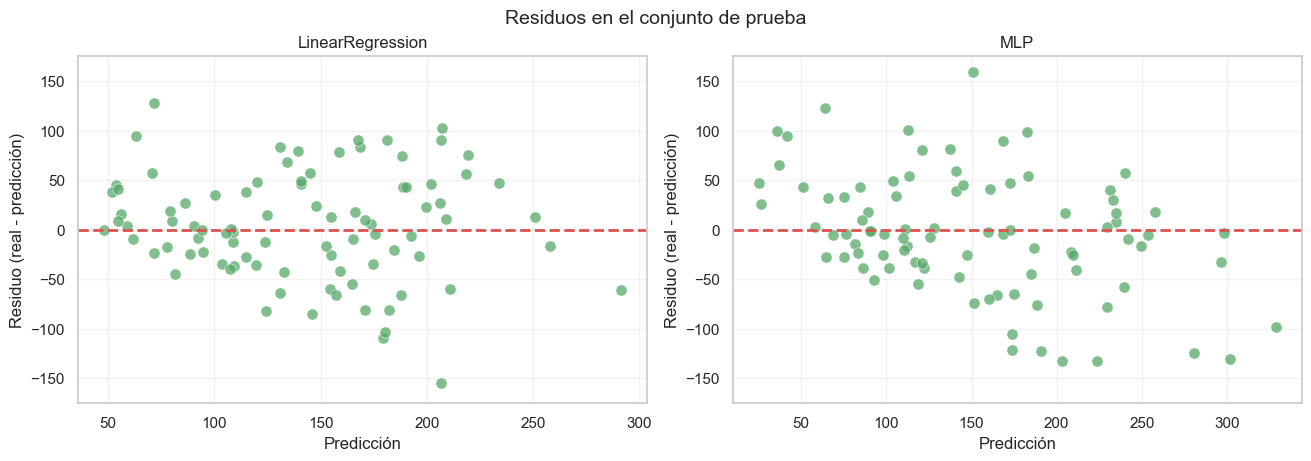


ERRORES ABSOLUTOS MÁS ALTOS — LinearRegression

Caso 1 (posición 61 dentro del conjunto de prueba)
  Valor real de progresión: 52.00
  Valor estimado:           206.49
  Error absoluto:           154.49 puntos
  Interpretación: El modelo SOBREESTIMÓ el valor real por 154.49 puntos.
  Características del caso:
Característica   Valor
           age -0.0418
           sex -0.0446
           bmi  0.0412
            bp -0.0263
            s1 -0.0318
            s2 -0.0304
            s3 -0.0360
            s4  0.0029
            s5  0.0337
            s6 -0.0176

Caso 2 (posición 46 dentro del conjunto de prueba)
  Valor real de progresión: 200.00
  Valor estimado:           71.67
  Error absoluto:           128.33 puntos
  Interpretación: El modelo SUBESTIMÓ el valor real por 128.33 puntos.
  Características del caso:
Característica   Valor
           age -0.0963
           sex -0.0446
           bmi -0.0364
            bp -0.0745
            s1 -0.0387
            s2 -0.0276
            

In [42]:
# Comparar Real vs. predicho de Regresión Lineal y MLP, lado a lado
nombres_graf = ["LinearRegression", "MLP"]
predicciones_graf = {}
residuos_graf = {}

for nombre in nombres_graf:
    modelo = modelos_reg_finales[nombre]
    modelo.fit(X_train_val, y_train_val)
    predicciones_graf[nombre] = modelo.predict(X_test)
    residuos_graf[nombre] = y_test - predicciones_graf[nombre]

limite = [min(y_test.min(), *(predicciones_graf[n].min() for n in nombres_graf)),
          max(y_test.max(), *(predicciones_graf[n].max() for n in nombres_graf))]
limite_residuo = max(abs(residuos_graf[n]).max() for n in nombres_graf)

# Los dos modelos comparten los mismos límites para comparar sus predicciones.
fig_pred, axes_pred = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
for ax, nombre in zip(axes_pred, nombres_graf):
    ax.scatter(y_test, predicciones_graf[nombre], alpha=0.75,
               color="#2878B5", edgecolor="white", linewidth=0.5, s=65)
    ax.plot(limite, limite, color="#D9534F", linestyle="--", linewidth=2,
            label="Predicción perfecta")
    ax.set_xlim(limite)
    ax.set_ylim(limite)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(nombre)
    ax.set_xlabel("Valor real")
    ax.set_ylabel("Predicción")
    ax.legend()
    ax.grid(alpha=0.25)
fig_pred.suptitle("Real vs. predicho en el conjunto de prueba", fontsize=14)
plt.show()

# Los residuos también se muestran lado a lado y con la misma escala vertical.
fig_res, axes_res = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, nombre in zip(axes_res, nombres_graf):
    ax.scatter(predicciones_graf[nombre], residuos_graf[nombre], alpha=0.75,
               color="#55A868", edgecolor="white", linewidth=0.5, s=65)
    ax.axhline(0, color="#D9534F", linestyle="--", linewidth=2)
    ax.set_ylim(-limite_residuo * 1.1, limite_residuo * 1.1)
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Residuo (real - predicción)")
    ax.grid(alpha=0.25)
fig_res.suptitle("Residuos en el conjunto de prueba", fontsize=14)
plt.show()

# Interpretación legible de los dos errores absolutos mayores por modelo
for nombre in nombres_graf:
    y_pred = predicciones_graf[nombre]
    residuos = residuos_graf[nombre]
    posiciones = np.argsort(np.abs(residuos))[-2:][::-1]

    print(f"\n{'=' * 68}")
    print(f"ERRORES ABSOLUTOS MÁS ALTOS — {nombre}")
    print(f"{'=' * 68}")

    for numero_caso, posicion in enumerate(posiciones, start=1):
        real = float(y_test[posicion])
        prediccion = float(y_pred[posicion])
        error = float(abs(residuos[posicion]))

        if prediccion < real:
            interpretacion = f"El modelo SUBESTIMÓ el valor real por {error:.2f} puntos."
        elif prediccion > real:
            interpretacion = f"El modelo SOBREESTIMÓ el valor real por {error:.2f} puntos."
        else:
            interpretacion = "La predicción coincide con el valor real."

        print(f"\nCaso {numero_caso} (posición {posicion} dentro del conjunto de prueba)")
        print(f"  Valor real de progresión: {real:.2f}")
        print(f"  Valor estimado:           {prediccion:.2f}")
        print(f"  Error absoluto:           {error:.2f} puntos")
        print(f"  Interpretación: {interpretacion}")
        print("  Características del caso:")
        tabla_caracteristicas = pd.DataFrame({
            "Característica": diabetes.feature_names,
            "Valor": [float(valor) for valor in X_test[posicion]],
        })
        print(tabla_caracteristicas.to_string(
            index=False,
            formatters={"Valor": lambda valor: f"{valor:.4f}"},
        ))

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
   - En prueba, Gradient Boosting obtuvo el menor MAE (42.55), el menor RMSE (52.40) y el mayor R² (0.4818). El resultado es el mejor de los modelos comparados en esta partición.

2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
   - MAE penaliza los errores linealmente, mientras que RMSE da más peso a los errores grandes. Por eso el orden de los modelos puede cambiar según la métrica.

3. ¿Cómo se interpreta un R² negativo?
   - En el conjunto evaluado significa que el error cuadrático del modelo es mayor que el de predecir la media del objetivo; el modelo resulta peor que esa referencia.

4. ¿Qué efecto tuvo aumentar la regularización?
   - En la comparación de validación, al subir alpha disminuyó la magnitud de los coeficientes. Ridge pasó de suma absoluta de coeficientes ≈198.22 a ≈87.80; su RMSE de validación fue mínimo con alpha = 1 (≈51.10). Lasso dejó coeficientes en cero al aumentar alpha (10 de 10 con alpha = 100); su RMSE de validación también fue mínimo con alpha = 1 (≈51.06), y con alpha altos aumentaron los errores de entrenamiento y validación.

5. ¿Qué puede explicar los errores grandes?
   - Pueden deberse a variabilidad de la progresión no capturada por las características, ruido o limitaciones del modelo. Los ejemplos con mayor error que imprime la celda permiten examinarlos, pero no bastan para afirmar que sean valores atípicos o errores de medición.

6. ¿Un coeficiente predictivo demuestra una relación causal?
   - No. Un coeficiente describe una asociación predictiva dentro del modelo; para sostener causalidad se requiere evidencia y un diseño causal apropiados.